# Monte Carlo Retirement Projection

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Simulates thousands of possible market paths for a portfolio with withdrawals, then shows the spread of outcomes as a percentile fan and the probability that the money lasts to each age. It replaces a single misleading 'expected' line with a range and a probability.

## When to use

- Retirement or endowment planning with regular withdrawals
- Communicate the risk of running out of money rather than an average outcome
- Compare plans (spending levels, allocations) by their probability of success

## Avoid when

- Presenting the median path as a forecast
- Hiding the return and inflation assumptions; results are only as good as these inputs
- Drawing all simulated paths (spaghetti); show percentile bands and a few sample paths

## Alternatives

- Fan chart
- Table of success probabilities by spending level

## Design tips

- Work in real (inflation-adjusted) dollars so the numbers mean today's purchasing power
- Show the probability of success as its own panel; it is the decision metric
- Use a one-hue fan: darker = more likely

## Example

$1.5M at age 60, $70k/year inflation-adjusted withdrawals, real returns ~4.5% ± 11% a year, 5,000 simulated paths (illustrative; not financial advice).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(2025)
n_paths, years = 5000, 35
start_age, start_wealth, spending = 60, 1_500_000, 70_000      # real (today's) dollars
mu, sigma = 0.045, 0.11                                         # real annual return, volatility
log_ret = rng.normal(np.log1p(mu) - sigma ** 2 / 2, sigma, (n_paths, years))

wealth = np.empty((n_paths, years + 1))
wealth[:, 0] = start_wealth
for t in range(years):                       # withdraw at the start of each year, then grow
    wealth[:, t + 1] = np.maximum((wealth[:, t] - spending) * np.exp(log_ret[:, t]), 0)
ages = start_age + np.arange(years + 1)
bands = pd.DataFrame(np.percentile(wealth, [10, 25, 50, 75, 90], axis=0).T / 1e6, index=ages,
                     columns=["p10", "p25", "p50", "p75", "p90"])
p_lasting = pd.Series((wealth > 0).mean(axis=0), index=ages)
bands.iloc[::5].round(2)

,p10,p25,p50,p75,p90
60,1.50,1.50,1.50,1.50,1.50
65,0.99,1.17,1.41,1.70,1.98
70,0.69,0.95,1.32,1.75,2.28
75,0.40,0.73,1.20,1.80,2.56
80,0.08,0.47,1.03,1.83,2.85
85,0.00,0.16,0.82,1.85,3.13
90,0.00,0.00,0.60,1.86,3.54
95,0.00,0.00,0.31,1.86,4.02


### Plot

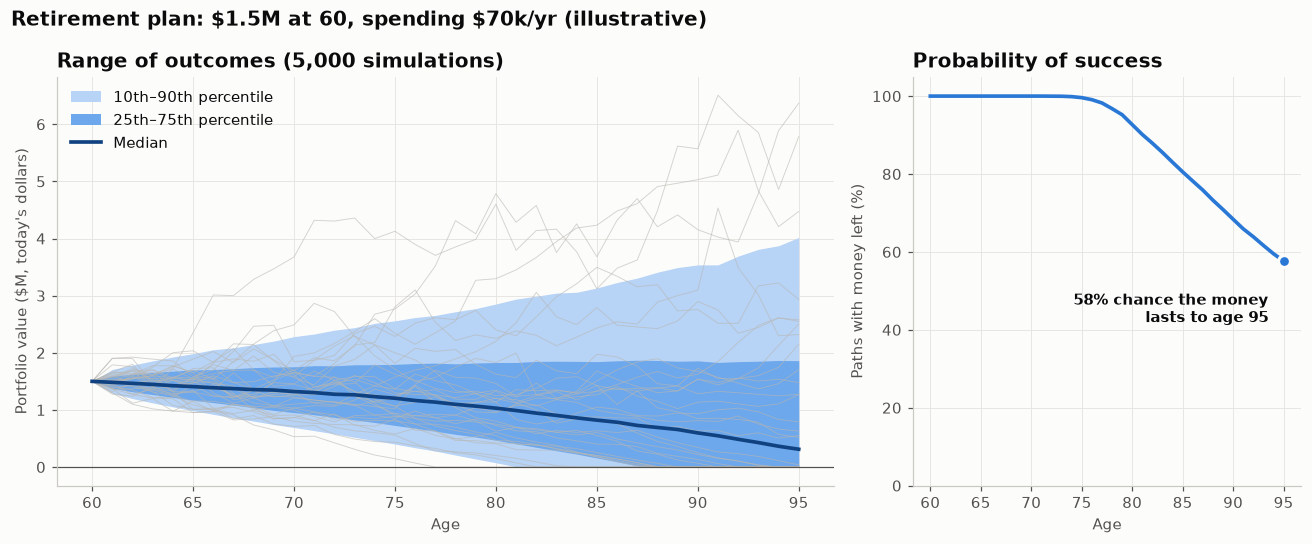

In [3]:
fig, (ax, axp) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})
for path in wealth[rng.choice(n_paths, 30, replace=False)]:
    ax.plot(ages, path / 1e6, color="#b8b7b1", linewidth=0.6, alpha=0.6)
ax.fill_between(ages, bands["p10"], bands["p90"], color="#b7d3f6", linewidth=0, label="10th–90th percentile")
ax.fill_between(ages, bands["p25"], bands["p75"], color="#6da7ec", linewidth=0, label="25th–75th percentile")
ax.plot(ages, bands["p50"], color="#104281", linewidth=2.4, label="Median")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Age")
ax.set_ylabel("Portfolio value ($M, today's dollars)")
ax.set_title("Range of outcomes (5,000 simulations)")
ax.legend(loc="upper left")

axp.plot(ages, p_lasting * 100, color=PALETTE[0], linewidth=2.4)
p95 = p_lasting.loc[95]
axp.scatter(95, p95 * 100, s=60, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=2, zorder=3)
axp.annotate(f"{p95:.0%} chance the money\nlasts to age 95", (95, p95 * 100), xytext=(-10, -40),
             textcoords="offset points", ha="right", fontsize=9.5, fontweight="bold")
axp.set_ylim(0, 105)
axp.set_xlabel("Age")
axp.set_ylabel("Paths with money left (%)")
axp.set_title("Probability of success")
fig.suptitle(r"Retirement plan: \$1.5M at 60, spending \$70k/yr (illustrative)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Half of the simulated paths end above the dark median line. The light band holds 80% of outcomes. The right panel shows the share of paths with money left at each age; read off the chance the money lasts to 95.

---
Standalone script: [`monte_carlo_wealth.py`](monte_carlo_wealth.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)